# A3.1 · Independent continual trajectories and the A4 rank-first controller

**Complete** · 414/414 matched decision states · 2,484 policy decisions · 2026-11-25T13:29:54+01:00.

## Design

Each of P1–P6 owns its MAE weights and AdamW state throughout a 23-clip walk. The six policies start together at the seed checkpoint. We repeat the matched experiment at six origin offsets and across three seeds. Updates use only the origin frame. The 11 A3 candidate actions, 0.003 base LR, 16 within-clip lookahead frames, 128 historical selection images and mask seeds follow A3. P3's candidate scores and chosen action are checked against the archived A3 trajectory at every decision.

| Policy | Committed decision |
|---|---|
| P1 | Always update encoder and decoder at 1×. |
| P2 | Always update decoder at 1×, freezing the encoder and its optimizer state. |
| P3 | Maximize reconstruction gain with the A3 rank guard (up to 0.1 calibration RMS of rank decline). |
| P4 | Maximize meaningful RankMe gain with no reconstruction decline. |
| P5 / A4 | Take P4's action when feasible. Otherwise maximize meaningful reconstruction gain with no RankMe decline. Skip when neither qualifies. |
| P6 | Maximize meaningful reconstruction gain with zero tolerance for RankMe decline. |

A meaningful gain exceeds 0.1 of the corresponding pre-experiment, seed-specific RMS action effect. The hierarchy uses separate thresholds and no weighted score. Candidate scores are measured independently on each policy's current model. Ties prefer the nondominated action and then the original action order.

**Fixed independent audits.** Before training and after each commitment we measure uncentered RankMe on the seed's original A2 historical audit bank of 128 captures. Reconstruction is mean masked per-image loss on a separate, fixed panel of 128 BDD100K validation captures, with the same images, order and mask at every step, for every seed and policy. Captures are excluded if present in the archived walk, native clips or archived probe list. The selector cannot read either audit. Only the two research metrics enter this report.

## Recalculate this snapshot

Run All with NumPy, SciPy, Matplotlib and IPython. The embedded archive contains every saved decision, each adaptive candidate’s absolute selection measurements, per-image audit losses, audit singular spectra, the protocol and worker source. Recalculation works offline. Retraining requires the registered images, original checkpoints and project environment.

In [ ]:
import base64, gzip, hashlib, json
from IPython.display import display, Markdown
archive = base64.b64decode(
    "..."
)
assert hashlib.sha256(archive).hexdigest() == "b91308dbe1b88fe1668f8d407899fb55d1b8e88ad141e9a7999511c68a628750"
payload = json.loads(gzip.decompress(archive))
spec, walks = payload["design"], payload["walks"]

In [ ]:
"""Recompute, inspect and plot the embedded A3.1 decision records."""
import numpy as np
from scipy.stats import t as student_t
import matplotlib.pyplot as plt

LABELS={"P1":"Tied 1×","P2":"Decoder 1×","P3":"Loss · tolerant guard",
        "P4":"Rank · loss guard","P5":"Rank first, then loss","P6":"Loss · strict guard"}
COLORS=["#9b6354","#364e77","#977521","#9a538d","#00786d","#4c8ba5"]


def check_decision(policy, raw, scales, spec):
    if policy in ("P1","P2"):
        return (7 if policy=="P1" else 2),"fixed"
    raw=np.asarray(raw)
    l=(raw[0,0]-raw[:,0])/scales["loss"][-1]
    r=(raw[:,1]-raw[0,1])/scales["rank"][1]
    def pick(score,guard,secondary):
        feasible=np.flatnonzero(guard & (score>spec["min_gain"]))
        if not len(feasible):return 0
        # Among equal target gains, a candidate with lower secondary gain is dominated.
        return int(max(feasible,key=lambda i:(score[i],secondary[i],-i)))
    if policy in ("P4","P5"):
        a=pick(r,l>=0,l)
        if a or policy=="P4":return a,("rank" if a else "skip")
    a=pick(l,r>=(-spec["rank_guard"] if policy=="P3" else 0),r)
    return a,("loss" if a else "skip")


def audit_values(audit):
    s=np.asarray(audit["spectrum"],dtype=np.float64)
    p=s/s.sum()+1e-7
    independent=float(np.exp(-(p*np.log(p)).sum()))
    np.testing.assert_allclose(independent,audit["rank"],rtol=2e-6,atol=2e-6)
    np.testing.assert_allclose(np.mean(audit["per_image"]),audit["loss"],rtol=0,atol=1e-12)
    return [audit["rank"],audit["loss"]]


def trajectories(spec,walks,verify=True):
    traces={}
    for w in walks:
        start=audit_values(w["start"]) if verify else [w["start"]["rank"],w["start"]["loss"]]
        track=[[start]*6]
        for i,row in enumerate(w["steps"]):
            assert row["clip"]==spec["clips"][i]
            current=[]
            for k in spec["policies"]:
                d=row[k]
                if verify:
                    assert check_decision(k,d["candidates"],spec["scales"][str(w["seed"])],spec)==(d["action"],d["mode"])
                    current.append(audit_values(d["audit"]))
                else:current.append([d["audit"]["rank"],d["audit"]["loss"]])
            assert current[1][0]==start[0]
            track.append(current)
        traces[w["seed"],w["walk"]]=np.array(track)
    return traces


def seed_averages(spec,traces):
    result=[]
    for seed in spec["seeds"]:
        paths=[traces.get((seed,j)) for j in range(len(spec["offsets"]))]
        if all(v is not None and len(v)==len(spec["clips"])+1 for v in paths):
            result.append(np.mean(paths,axis=0))
    return np.asarray(result)


def ci(x):
    x=np.asarray(x); mean=x.mean(axis=0)
    if len(x)<2:return mean, np.full_like(mean,np.nan),np.full_like(mean,np.nan)
    width=student_t.ppf(.975,len(x)-1)*x.std(axis=0,ddof=1)/np.sqrt(len(x))
    return mean,mean-width,mean+width


def interval(x):
    m,lo,hi=ci(x)
    return f"{m:+.5f} [{lo:+.5f}, {hi:+.5f}]" if np.isfinite(lo) else f"{m:+.5f} (one seed)"


def history_plot(spec,traces):
    allseeds=seed_averages(spec,traces)
    if len(allseeds):
        means=allseeds.mean(axis=0); caption=f"{len(allseeds)} completed seed(s), six walks per seed"
    else:
        complete=[v for v in traces.values() if len(v)==len(spec["clips"])+1]
        if complete:
            means=np.mean(complete,axis=0);caption=f"{len(complete)} completed walk(s)"
        else:
            means=max(traces.values(),key=len);caption="first walk in progress"
    fig,axes=plt.subplots(1,2,figsize=(12,4.6),layout="constrained")
    for j,ax in enumerate(axes):
        for i,(k,color) in enumerate(zip(spec["policies"],COLORS)):
            ax.plot(np.arange(len(means)),means[:,i,j],color=color,linewidth=2.4 if k=="P5" else 1.5,
                    linestyle="--" if k=="P2" else "-",label=f"{k}  {LABELS[k]}")
        ax.set(xlabel="Committed decisions",ylabel=["Historical audit RankMe","Masked reconstruction loss"][j],
               title=["Fixed historical audit bank · higher is better","Fixed reconstruction audit panel · lower is better"][j])
        ax.spines[["top","right"]].set_visible(False);ax.grid(axis="y",alpha=.2)
    axes[1].legend(frameon=False,fontsize=8)
    fig.suptitle(f"Absolute measurements from step zero · {caption}")
    return fig


def paired_plot(seeds):
    diff=seeds[:,:,4,:]-seeds[:,:,1,:]
    fig,axes=plt.subplots(1,2,figsize=(12,3.8),layout="constrained")
    for i,ax in enumerate(axes):
        m,lo,hi=ci(diff[:,:,i]); x=np.arange(len(m))
        for seed in diff:ax.plot(x,seed[:,i],color="#a4b9b8",lw=.8)
        ax.axhline(0,color="#65717d",lw=.7);ax.plot(x,m,color="#00786d",lw=2)
        if len(seeds)>=2:ax.fill_between(x,lo,hi,color="#00786d",alpha=.16)
        ax.set(xlabel="Committed decisions",ylabel=["RankMe difference","Reconstruction loss difference"][i],
               title=["Positive favors P5","Negative favors P5"][i])
    fig.suptitle("P5 minus decoder-only P2 · paired seed differences")
    return fig


def tables(spec,walks,traces):
    seeds=seed_averages(spec,traces)
    text=["### Endpoint change from step zero",""]
    if len(seeds):
        text+=["Absolute metrics are plotted above. Endpoint changes below average the six walks within each complete seed. Brackets give 95% Student t intervals across paired seed-level changes. The clip order and audit panels are fixed. Three seeds give limited precision. Intervals are pointwise and unadjusted for multiple comparisons.","",
               "| Policy | Historical audit RankMe change | Audit reconstruction loss change |","|---|---:|---:|"]
        delta=seeds[:,-1]-seeds[:,0]
        for i,k in enumerate(spec["policies"]):text.append(f"| {k} · {LABELS[k]} | {interval(delta[:,i,0])} | {interval(delta[:,i,1])} |")
        text+=["","### Absolute final measurements","",
               "| Policy | Historical audit RankMe | Audit reconstruction loss |","|---|---:|---:|"]
        for i,k in enumerate(spec["policies"]):
            endpoint=seeds[:,-1,i].mean(axis=0)
            text.append(f"| {k} | {endpoint[0]:.5f} | {endpoint[1]:.5f} |")
        diff=seeds[:,:,4]-seeds[:,:,1]
        text+=["","### P5 compared with decoder-only P2","",
               "| Paired difference | Historical RankMe | Reconstruction loss |","|---|---:|---:|",
               f"| At final decision | {interval(diff[:,-1,0])} | {interval(diff[:,-1,1])} |",
               f"| Mean over all 23 post-decision measurements | {interval(diff[:,1:,0].mean(1))} | {interval(diff[:,1:,1].mean(1))} |"]
    else:text.append("Endpoint estimates appear after all six walks of a seed finish.")
    rows=[s for w in walks for s in w["steps"]]
    if rows:
        text+=["","### What each policy actually committed","",
               "| Policy | Skip | Decoder only | Encoder only | Both | Rank-priority choices | Loss-priority choices |","|---|---:|---:|---:|---:|---:|---:|"]
        for k in spec["policies"]:
            entries=[row[k] for row in rows]; acts=[spec["actions"][v["action"]] for v in entries]
            e=np.array([v["encoder"]>0 for v in acts]);d=np.array([v["decoder"]>0 for v in acts])
            shares=[(~e&~d).mean(),(~e&d).mean(),(e&~d).mean(),(e&d).mean()]
            ranks=sum(v["mode"]=="rank" for v in entries);losses=sum(v["mode"]=="loss" for v in entries)
            text.append(f"| {k} | "+" | ".join(f"{v:.1%}" for v in shares)+f" | {ranks} | {losses} |")
    if rows:
        text+=["","### What happened on P5's rank and reconstruction decisions?","",
               "Absolute fixed-audit measurements immediately after each commitment are differenced against the preceding step of the same walk. These conditional averages describe selected events.","",
               "| P5 stage | Decisions | Encoder updated | Mean rank change | Mean loss change |","|---|---:|---:|---:|---:|"]
        events={"rank":[],"loss":[],"skip":[]}
        for w in walks:
            index=(w["seed"],w["walk"])
            changes=np.diff(traces[index][:,4,:],axis=0)
            for step,delta in zip(w["steps"],changes):
                picked=step["P5"]
                events[picked["mode"]].append((spec["actions"][picked["action"]]["encoder"]>0,*delta))
        for stage,group in events.items():
            if group:
                enc,rank,loss=np.mean(group,axis=0)
                text.append(f"| {stage} | {len(group)} | {enc:.1%} | {rank:+.6f} | {loss:+.6f} |")
            else:text.append(f"| {stage} | 0 | — | — | — |")
    return "\n".join(text)

traces = trajectories(spec, walks, verify=True)
seeds = seed_averages(spec, traces)

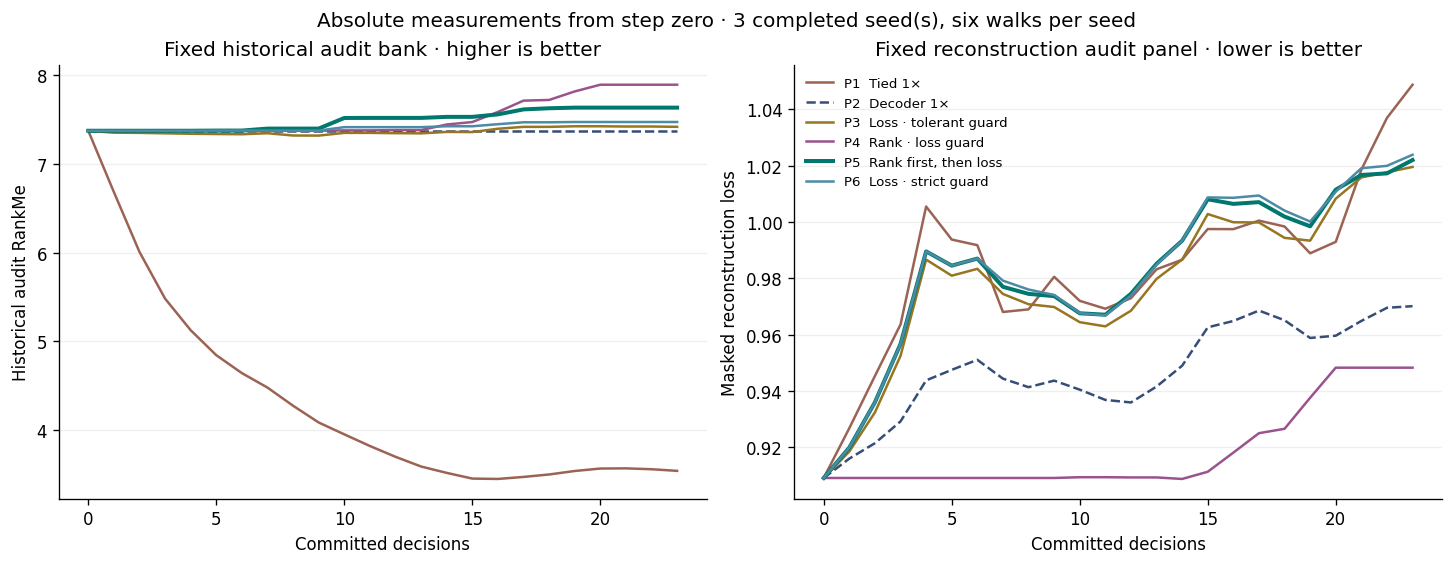

In [ ]:
history_plot(spec, traces); plt.show()

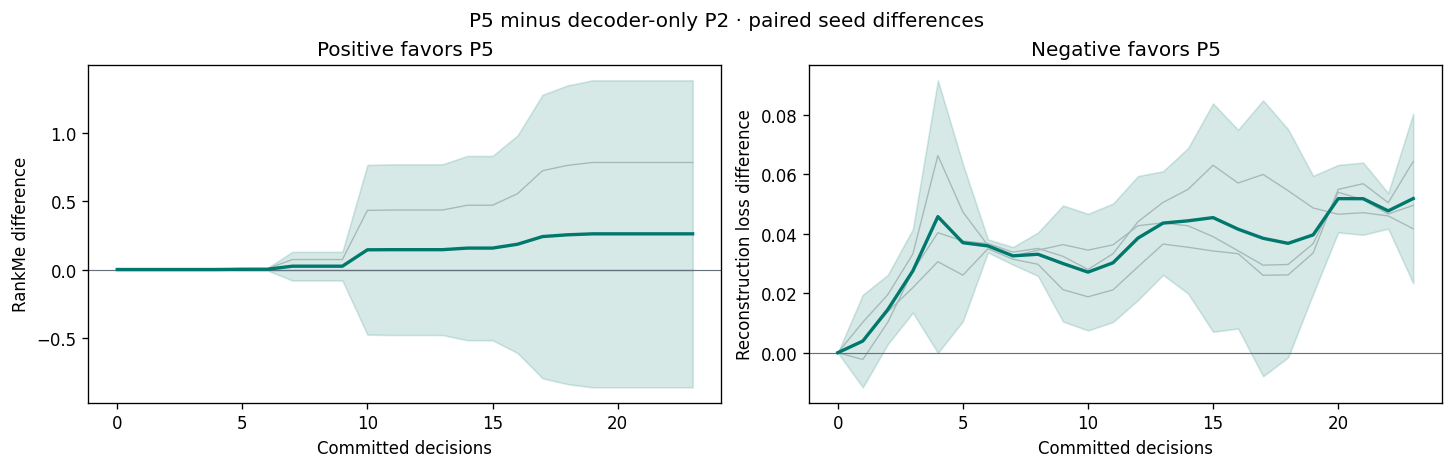

In [ ]:
paired_plot(seeds); plt.show()

In [ ]:
display(Markdown(tables(spec, walks, traces)))

### Endpoint change from step zero

Absolute metrics are plotted above. Endpoint changes below average the six walks within each complete seed. Brackets give 95% Student t intervals across paired seed-level changes. The clip order and audit panels are fixed. Three seeds give limited precision. Intervals are pointwise and unadjusted for multiple comparisons.

| Policy | Historical audit RankMe change | Audit reconstruction loss change |
|---|---:|---:|
| P1 · Tied 1× | -3.84036 [-5.26959, -2.41112] | +0.13961 [+0.09427, +0.18496] |
| P2 · Decoder 1× | +0.00000 [+0.00000, +0.00000] | +0.06100 [+0.02233, +0.09967] |
| P3 · Loss · tolerant guard | +0.04409 [-0.71354, +0.80172] | +0.11042 [+0.04176, +0.17909] |
| P4 · Rank · loss guard | +0.51979 [-0.44148, +1.48105] | +0.03916 [-0.02923, +0.10754] |
| P5 · Rank first, then loss | +0.26098 [-0.86192, +1.38387] | +0.11287 [+0.04592, +0.17982] |
| P6 · Loss · strict guard | +0.09879 [-0.32628, +0.52386] | +0.11475 [+0.04953, +0.17996] |

### Absolute final measurements

| Policy | Historical audit RankMe | Audit reconstruction loss |
|---|---:|---:|
| P1 | 3.53452 | 1.04874 |
| P2 | 7.37488 | 0.97012 |
| P3 | 7.41898 | 1.01955 |
| P4 | 7.89467 | 0.94828 |
| P5 | 7.63586 | 1.02200 |
| P6 | 7.47367 | 1.02387 |

### P5 compared with decoder-only P2

| Paired difference | Historical RankMe | Reconstruction loss |
|---|---:|---:|
| At final decision | +0.26098 [-0.86192, +1.38387] | +0.05187 [+0.02333, +0.08041] |
| Mean over all 23 post-decision measurements | +0.12846 [-0.42427, +0.68120] | +0.03694 [+0.02596, +0.04792] |

### What each policy actually committed

| Policy | Skip | Decoder only | Encoder only | Both | Rank-priority choices | Loss-priority choices |
|---|---:|---:|---:|---:|---:|---:|
| P1 | 0.0% | 0.0% | 0.0% | 100.0% | 0 | 0 |
| P2 | 0.0% | 100.0% | 0.0% | 0.0% | 0 | 0 |
| P3 | 11.1% | 78.3% | 0.7% | 9.9% | 0 | 368 |
| P4 | 92.3% | 0.0% | 0.0% | 7.7% | 32 | 0 |
| P5 | 15.7% | 79.0% | 0.7% | 4.6% | 17 | 332 |
| P6 | 14.7% | 82.9% | 0.0% | 2.4% | 0 | 353 |

### What happened on P5's rank and reconstruction decisions?

Absolute fixed-audit measurements immediately after each commitment are differenced against the preceding step of the same walk. These conditional averages describe selected events.

| P5 stage | Decisions | Encoder updated | Mean rank change | Mean loss change |
|---|---:|---:|---:|---:|
| rank | 17 | 100.0% | +0.266080 | -0.003433 |
| loss | 332 | 1.5% | +0.000525 | +0.006295 |
| skip | 65 | 0.0% | +0.000000 | +0.000000 |

## Inspect a decision or the worker

The record below includes the chosen action, policy stage, all measured candidate scores for an adaptive policy and both fixed audits. Set the indices or policy to examine another decision. The sources dictionary contains the archived training implementation.

In [ ]:
if walks and walks[0]["steps"]:
    walk, step, policy = 0, 0, "P5"
    display(walks[walk]["steps"][step][policy])
print(list(payload["sources"]))
# print(payload["sources"]["mae-continual-a31/run_continual.py"])